In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
out = "./results/accellerated/tolerance/ffd"


pd_ris = pd.read_csv(f"{out}/LeastSquares_50.csv")



In [5]:
labels = list(set(pd_ris['directions'].values))
num_directions = list(set(pd_ris['gamma'].values))
num_directions.sort()

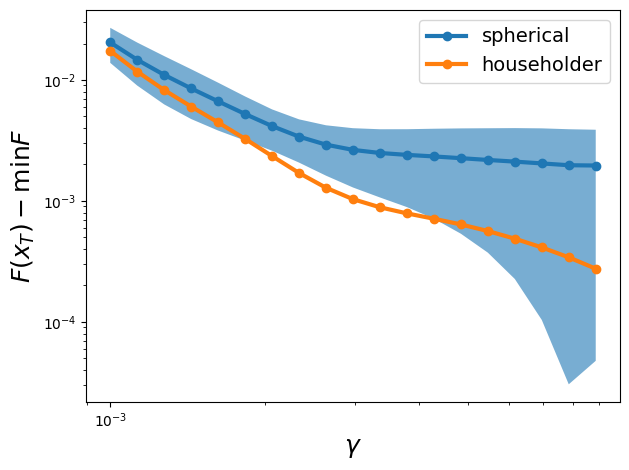

In [7]:

label_map = {
    'spherical' : 'unstructured',
    'householder' : 'structured',
}

fig, ax = plt.subplots()
for label in labels:
    mu_err  = pd_ris[pd_ris['directions'] == label ]['mu_last_val'].values[:-1]
    std_err = pd_ris[pd_ris['directions'] == label ]['std_last_val'].values[:-1]
    ax.plot(num_directions[:-1], mu_err, 'o-', lw=3, label=label)
    ax.fill_between(num_directions[:-1], mu_err - std_err, mu_err + std_err, alpha=0.6 )
    
#ax.axhline(1e-1, linestyle='--')
ax.set_xscale('log')
ax.set_yscale("log")
ax.set_ylabel("$ F(x_T) - \\min F $",fontsize=18)
ax.set_xlabel("$\\gamma$", fontsize=18)
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("./stepsize.png", bbox_inches='tight')

In [8]:
mu_sph, std_sph = [], []
results = {}



for label in labels:
    results[label] = [[], []]
    with open(f"./results/accellerated/conv_speed/ffd/LeastSquares_50_{label}_best", 'r') as f:
        for line in f.readlines():
            splitted = line.split(",")
            results[label][0].append(float(splitted[0]))
            results[label][1].append(float(splitted[1]))
    results[label][0] = np.array(results[label][0])
    results[label][1] = np.array(results[label][1])


# with open("./results/conv_speed/ffd/LeastSquares_100_100_spherical_best", 'r') as f:
#     for line in f.readlines():
#         splitted = line.split(",")
#         mu_sph.append(float(splitted[0]))
#         std_sph.append(float(splitted[1]))
# mu_sph, std_sph = np.array(mu_sph), np.array(std_sph)

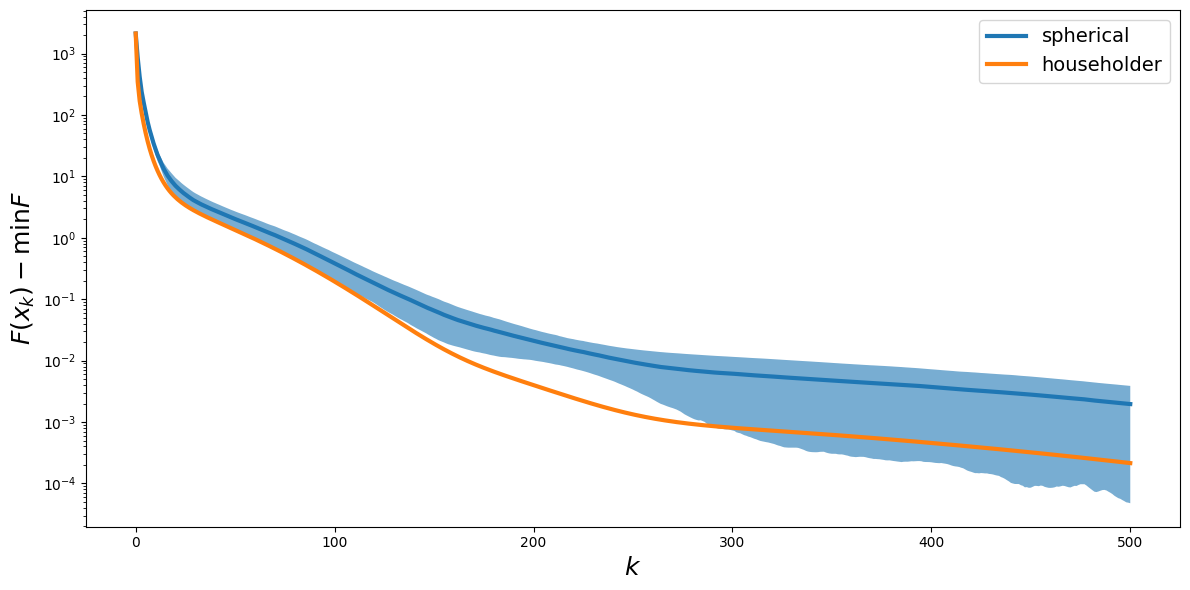

In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

for (label, (mu, std)) in results.items():
    ax.plot(range(len(mu)), mu, '-', lw=3, label=label)
    ax.fill_between(range(len(mu)), mu - std, mu + std, alpha=0.6)
# ax.plot(range(len(mu_h)), mu_h, '-', lw=3, label='structured')
# ax.fill_between(range(len(mu_h)), mu_h - std_h, mu_h + std_h, alpha=0.6)


ax.set_xlabel("$k$", fontsize=18)
ax.set_ylabel("$F(x_k) - \min F$", fontsize=18)
ax.set_yscale('log')
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("./acc.png", bbox_inches='tight')

In [15]:
num_directions[ np.argmin(pd_ris[pd_ris['directions'] == 'spherical' ]['mu_last_val'].values[:]) ]

0.0088586679041008

In [16]:
num_directions[ np.argmin(pd_ris[pd_ris['directions'] == 'householder' ]['mu_last_val'].values[:]) ]

0.01

In [17]:
methods = [
    'coordinate',
   'gaussian',
   'spherical',
   'householder',
   'butterfly',
   'butterfly_dct',
   'qr'
]

In [18]:
mu_sph, std_sph = [], []
results = {}



for label in methods:
    results[label] = [[], []]
    with open(f"./results/conv_speed/ffd/LeastSquares_100_100_1e-05_{label}_best", 'r') as f:
        for line in f.readlines():
            splitted = line.split(",")
            results[label][0].append(float(splitted[0]))
            results[label][1].append(float(splitted[1]))
    results[label][0] = np.array(results[label][0])
    results[label][1] = np.array(results[label][1])


# with open("./results/conv_speed/ffd/LeastSquares_100_100_spherical_best", 'r') as f:
#     for line in f.readlines():
#         splitted = line.split(",")
#         mu_sph.append(float(splitted[0]))
#         std_sph.append(float(splitted[1]))
# mu_sph, std_sph = np.array(mu_sph), np.array(std_sph)

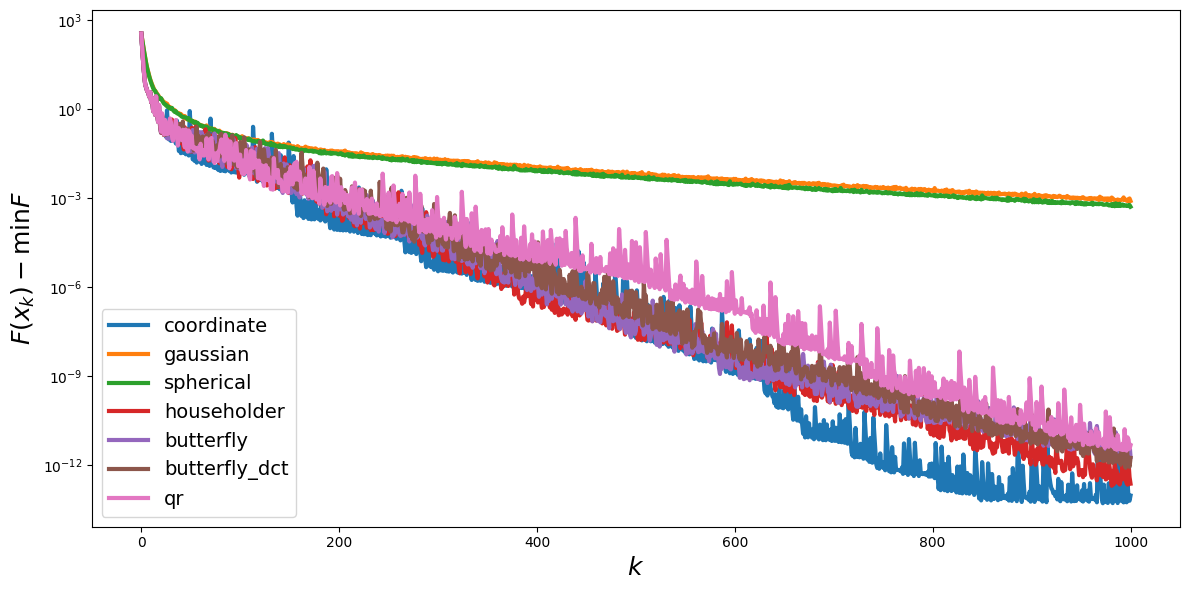

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))

for (label, (mu, std)) in results.items():
    ax.plot(range(len(mu)), mu, '-', lw=3, label=label)
#    ax.fill_between(range(len(mu)), mu - std, mu + std, alpha=0.6)
# ax.plot(range(len(mu_h)), mu_h, '-', lw=3, label='structured')
# ax.fill_between(range(len(mu_h)), mu_h - std_h, mu_h + std_h, alpha=0.6)


ax.set_xlabel("$k$", fontsize=18)
ax.set_ylabel("$F(x_k) - \min F$", fontsize=18)
ax.set_yscale('log')
ax.legend(fontsize=14)
fig.tight_layout()
fig.savefig("./polyak.png", bbox_inches='tight')

In [39]:
l = 2
for h in [1e-7]:#[1e-1, 1e-3, 1e-5, 1e-7]:
    mu_sph, std_sph = [], []
    results = {}



    for label in methods:
        results[label] = [[], []]
        with open(f"./results/conv_speed/ffd/LeastSquares_100_{l}_{h}_{label}_best", 'r') as f:
            for line in f.readlines():
                splitted = line.split(",")
                results[label][0].append(float(splitted[0]))
                results[label][1].append(float(splitted[1]))
        results[label][0] = np.array(results[label][0])
        results[label][1] = np.array(results[label][1])

    fig, ax = plt.subplots(figsize=(12, 6))

    for (label, (mu, std)) in results.items():
        ax.plot(range(len(mu)), mu, '-', lw=3, label=label)
    #    ax.fill_between(range(len(mu)), mu - std, mu + std, alpha=0.6)
    # ax.plot(range(len(mu_h)), mu_h, '-', lw=3, label='structured')
    # ax.fill_between(range(len(mu_h)), mu_h - std_h, mu_h + std_h, alpha=0.6)

    ax.set_title(f"Least Squares [$h_k = ${h} / k]", fontsize=20)
    ax.set_xlabel("$k$", fontsize=18)
    ax.set_ylabel("$F(x_k) - \min F$", fontsize=18)
    ax.set_yscale('log')
    ax.legend(fontsize=14)
    fig.tight_layout()
    fig.savefig(f"./polyak_{l}_{h}.png", bbox_inches='tight')
    plt.close(fig)